# Prediksi S&P 500: Perbandingan Model (versi perbaikan)

Perbaikan utama dari versi sebelumnya:
- Target = **return hari berikutnya**, bukan harga level (Decision Tree tidak bisa ekstrapolasi harga yang naik terus).
- Tidak ada *data leakage*: fitur hari *t* hanya memakai data sampai hari *t*.
- Split kronologis dan tuning dengan `TimeSeriesSplit`.
- Ada **baseline naif** sebagai pembanding wajib.
- `StandardScaler` hanya dipakai untuk model yang butuh (Ridge), lewat `Pipeline`.
- "Forecast masa depan" dari data test dihapus karena secara logika keliru.
- Ada uji signifikansi **Diebold-Mariano** dan **walk-forward validation** (dengan biaya transaksi) supaya kesimpulan tidak bergantung pada satu split.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn import metrics
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

RANDOM_STATE = 42

## 1. Ambil data

In [2]:
raw = yf.download("^GSPC", start="2021-01-01", end="2025-12-31", auto_adjust=True, progress=False)
raw.columns = raw.columns.get_level_values(0)      # buang level 'Ticker'
raw.index.name = "Date"
raw.to_csv("sp500_data.csv")
print(raw.shape)
raw.tail()

(1254, 5)


Price,Close,High,Low,Open,Volume
Date,,,,,
2025-12-23,6909.790039,6910.879883,6868.810059,6872.410156,3820560000
2025-12-24,6932.049805,6937.319824,6904.910156,6904.910156,1798270000
2025-12-26,6929.939941,6945.770020,6921.600098,6936.020020,2586550000
2025-12-29,6905.740234,6920.209961,6888.759766,6903.600098,3541750000
2025-12-30,6896.240234,6913.250000,6893.470215,6900.439941,3309930000


## 2. Feature engineering

Semua fitur dihitung dari data sampai hari *t*. Target adalah return hari *t+1*.

In [3]:
df = raw[["Open", "High", "Low", "Close", "Volume"]].copy()

# Return harian dan lag-nya. ret_lagK = return K hari sebelum hari ini (t)
#   ret_lag0 = return hari ini, ret_lag1 = kemarin, dst.
df["ret"] = df["Close"].pct_change()
for k in (0, 1, 2, 4):
    df[f"ret_lag{k}"] = df["ret"].shift(k)

# Fitur candle / range
df["hl_range"] = (df["High"] - df["Low"]) / df["Close"]
df["oc_change"] = (df["Close"] - df["Open"]) / df["Open"]

# Tren & volatilitas
df["ma5_ratio"] = df["Close"] / df["Close"].rolling(5).mean() - 1
df["ma20_ratio"] = df["Close"] / df["Close"].rolling(20).mean() - 1
df["vol5"] = df["ret"].rolling(5).std()
df["vol20"] = df["ret"].rolling(20).std()

# Volume (hati-hati volume = 0 -> inf)
df["vol_chg"] = df["Volume"].pct_change().replace([np.inf, -np.inf], np.nan)

# Target: return hari berikutnya
df["target"] = df["ret"].shift(-1)

features = ["ret_lag0", "ret_lag1", "ret_lag2", "ret_lag4", "hl_range", "oc_change",
            "ma5_ratio", "ma20_ratio", "vol5", "vol20", "vol_chg"]
X_latest = df[features].iloc[[-1]]            # baris terakhir (target-nya belum ada), dipakai untuk prediksi besok
df = df.dropna()
X, y = df[features], df["target"]
print(X.shape, "| fitur:", len(features))

(1232, 11) | fitur: 11


## 3. Split kronologis (tanpa shuffle)

In [4]:
split = int(len(df) * 0.74)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
print("Train:", X_train.index.min().date(), "->", X_train.index.max().date())
print("Test :", X_test.index.min().date(), "->", X_test.index.max().date())

Train: 2021-02-02 -> 2024-09-17
Test : 2024-09-18 -> 2025-12-29


## 4. Definisi model dan tuning

Tuning memakai `TimeSeriesSplit` agar fold validasi selalu lebih baru dari fold training.

In [5]:
tscv = TimeSeriesSplit(n_splits=5)

models = {
    "Baseline (rata-rata train)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge": GridSearchCV(
        make_pipeline(StandardScaler(), Ridge()),
        {"ridge__alpha": [0.1, 1, 10, 100, 1000]},
        cv=tscv, scoring="neg_mean_absolute_error"),
    "Decision Tree": GridSearchCV(
        DecisionTreeRegressor(random_state=RANDOM_STATE),
        {"max_depth": [2, 3, 4, 5], "min_samples_leaf": [10, 20, 40]},
        cv=tscv, scoring="neg_mean_absolute_error"),
    "Random Forest": GridSearchCV(
        RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
        {"max_depth": [2, 3, 5], "min_samples_leaf": [10, 20, 40]},
        cv=tscv, scoring="neg_mean_absolute_error"),
    "Gradient Boosting": GridSearchCV(
        GradientBoostingRegressor(random_state=RANDOM_STATE),
        {"n_estimators": [50, 100], "max_depth": [2, 3], "learning_rate": [0.03, 0.1], "subsample": [0.7]},
        cv=tscv, scoring="neg_mean_absolute_error"),
}

preds = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    preds[name] = m.predict(X_test)
    if hasattr(m, "best_params_"):
        print(f"{name:20s} best params: {m.best_params_}")

Ridge                best params: {'ridge__alpha': 1000}
Decision Tree        best params: {'max_depth': 2, 'min_samples_leaf': 40}
Random Forest        best params: {'max_depth': 2, 'min_samples_leaf': 40}
Gradient Boosting    best params: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 50, 'subsample': 0.7}


## 5. Evaluasi

Metrik pada **return** (MAE, RMSE, R², akurasi arah) dan MAE pada **harga** (return diprediksi dikonversi kembali ke harga penutupan besok). Baseline "persistence" = harga besok sama dengan harga hari ini.

In [6]:
close_today = df["Close"].iloc[split:]
actual_price = close_today * (1 + y_test)

rows = []
for name, p in preds.items():
    price_pred = close_today * (1 + p)
    rows.append({
        "Model": name,
        "MAE return": metrics.mean_absolute_error(y_test, p),
        "RMSE return": np.sqrt(metrics.mean_squared_error(y_test, p)),
        "R2 return": metrics.r2_score(y_test, p),
        "Akurasi arah": np.mean(np.sign(p) == np.sign(y_test)),
        "MAE harga": metrics.mean_absolute_error(actual_price, price_pred),
    })

# Persistence: harga besok = harga hari ini (return diprediksi = 0)
rows.append({
    "Model": "Persistence (harga besok = hari ini)",
    "MAE return": metrics.mean_absolute_error(y_test, np.zeros(len(y_test))),
    "RMSE return": np.sqrt(metrics.mean_squared_error(y_test, np.zeros(len(y_test)))),
    "R2 return": metrics.r2_score(y_test, np.zeros(len(y_test))),
    "Akurasi arah": np.nan,
    "MAE harga": metrics.mean_absolute_error(actual_price, close_today),
})

results = pd.DataFrame(rows).set_index("Model").round(5)
results.sort_values("MAE harga")

,MAE return,RMSE return,R2 return,Akurasi arah,MAE harga
Model,,,,,
Baseline (rata-rata train),0.00689,0.01102,-0.00046,0.57321,41.17356
Gradient Boosting,0.00692,0.01094,0.01355,0.55452,41.37923
Persistence (harga besok = hari ini),0.00694,0.01104,-0.00402,NaN,41.46538
Ridge,0.00694,0.01098,0.00643,0.52336,41.47410
Random Forest,0.00697,0.01107,-0.00991,0.52336,41.68232
Linear Regression,0.00698,0.01089,0.02339,0.52648,41.80587
Decision Tree,0.00712,0.01135,-0.06149,0.56075,42.54650


**Cara membaca:** model dikatakan berguna hanya jika MAE/RMSE lebih rendah dari baseline dan R² return > 0 secara konsisten. Akurasi arah di kisaran 50-55% tanpa selisih jelas dari baseline berarti tidak ada sinyal prediktif yang dapat diandalkan.

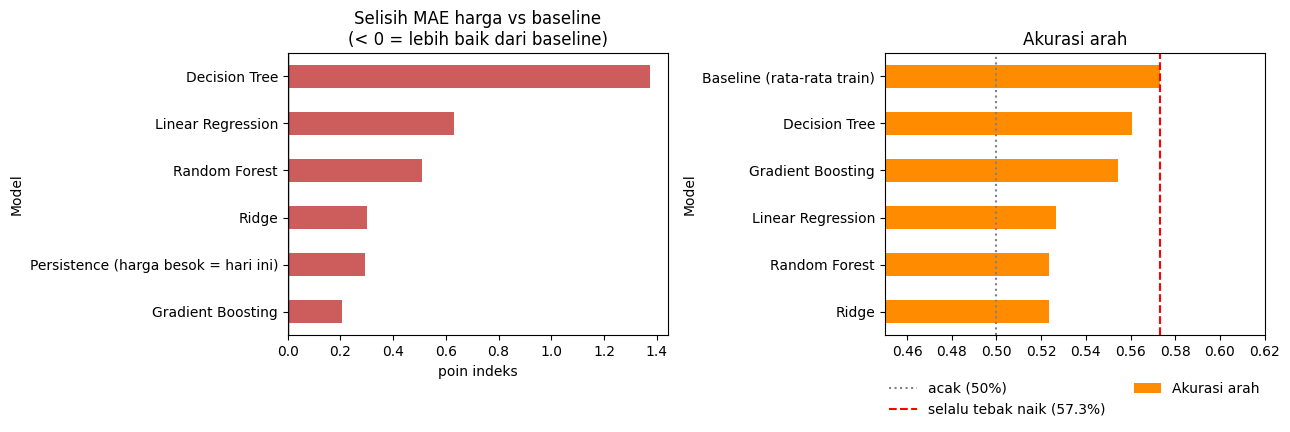

In [7]:
base_mae = results.loc["Baseline (rata-rata train)", "MAE harga"]
always_up = np.mean(y_test > 0)          # akurasi arah jika selalu menebak "naik"

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Kiri: selisih MAE harga terhadap baseline (zoom ke perbedaan yang sebenarnya)
diff = (results["MAE harga"] - base_mae).drop(index="Baseline (rata-rata train)").sort_values()
diff.plot.barh(ax=axes[0], color=["seagreen" if v < 0 else "indianred" for v in diff])
axes[0].axvline(0, color="black", lw=1)
axes[0].set_title("Selisih MAE harga vs baseline\n(< 0 = lebih baik dari baseline)")
axes[0].set_xlabel("poin indeks")

# Kanan: akurasi arah dengan garis acak dan garis "selalu naik"
acc = results["Akurasi arah"].dropna().sort_values()
acc.plot.barh(ax=axes[1], color="darkorange", legend=False)
axes[1].axvline(0.5, color="gray", ls=":", label="acak (50%)")
axes[1].axvline(always_up, color="red", ls="--", label=f"selalu tebak naik ({always_up:.1%})")
axes[1].set_xlim(0.45, 0.62)
axes[1].set_title("Akurasi arah")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)

plt.tight_layout(); plt.show()

## 6. Uji signifikansi: Diebold-Mariano

Selisih kecil antar model bisa saja hanya noise. Uji Diebold-Mariano (dengan koreksi Harvey untuk sampel kecil) menguji apakah selisih galat prediksi model vs baseline signifikan secara statistik.

- Statistik DM **negatif** = model lebih baik dari baseline, **positif** = lebih buruk.
- `p < 0.05` = selisih signifikan. Karena prediksi 1 hari ke depan, galat antar hari praktis tidak berkorelasi sehingga varians sederhana sudah memadai.

In [8]:
from scipy import stats

def diebold_mariano(y_true, p_model, p_ref, loss="se"):
    e_m = np.asarray(y_true) - np.asarray(p_model)
    e_r = np.asarray(y_true) - np.asarray(p_ref)
    d = (e_m**2 - e_r**2) if loss == "se" else (np.abs(e_m) - np.abs(e_r))
    n = len(d)
    dm = d.mean() / np.sqrt(d.var(ddof=1) / n)
    dm *= np.sqrt((n - 1) / n)                       # koreksi Harvey (h = 1)
    p = 2 * (1 - stats.t.cdf(abs(dm), df=n - 1))
    return dm, p

def dm_table(pred_dict, y_true, ref="Baseline (rata-rata train)"):
    rows = []
    for name, p in pred_dict.items():
        if name == ref:
            continue
        dm_se, p_se = diebold_mariano(y_true, p, pred_dict[ref], "se")
        dm_ae, p_ae = diebold_mariano(y_true, p, pred_dict[ref], "ae")
        sig = [("lebih baik" if dm < 0 else "lebih buruk") for dm, p in ((dm_se, p_se), (dm_ae, p_ae)) if p < 0.05]
        rows.append({"Model": name, "DM (kuadrat)": dm_se, "p (kuadrat)": p_se,
                     "DM (absolut)": dm_ae, "p (absolut)": p_ae,
                     "Signifikan vs baseline?": " / ".join(sorted(set(sig))) if sig else "tidak"})
    return pd.DataFrame(rows).set_index("Model").round(4)

dm_table(preds, y_test)

,DM (kuadrat),p (kuadrat),DM (absolut),p (absolut),Signifikan vs baseline?
Model,,,,,
Linear Regression,-0.7137,0.4759,1.0999,0.2722,tidak
Ridge,-0.6375,0.5243,1.5936,0.1120,tidak
Decision Tree,3.6655,0.0003,2.5117,0.0125,lebih buruk
Random Forest,0.8790,0.3800,2.1448,0.0327,lebih buruk
Gradient Boosting,-0.7374,0.4614,0.5644,0.5729,tidak


## 7. Prediksi vs aktual (data test)

Model terbaik (MAE harga): Gradient Boosting


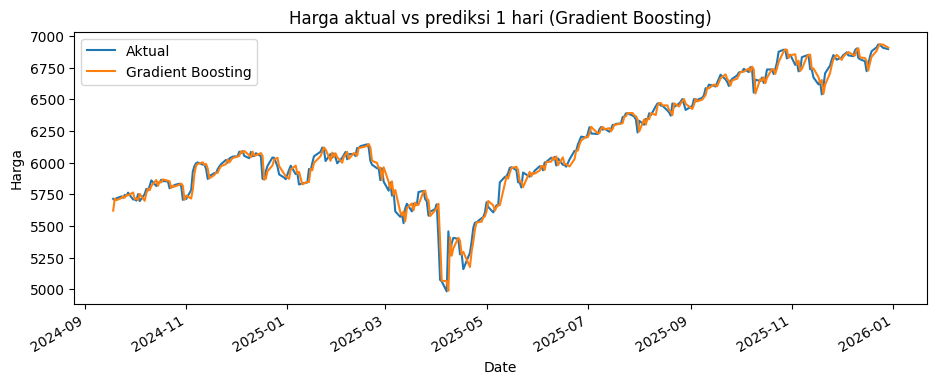

In [9]:
candidates = results.drop(index=["Persistence (harga besok = hari ini)", "Baseline (rata-rata train)"])
best_name = candidates["MAE harga"].idxmin()
print("Model terbaik (MAE harga):", best_name)

plot_df = pd.DataFrame({
    "Aktual": actual_price,
    best_name: close_today * (1 + preds[best_name]),
})
plot_df.plot(figsize=(11, 4), title=f"Harga aktual vs prediksi 1 hari ({best_name})")
plt.ylabel("Harga"); plt.show()

## 8. Uji strategi sederhana (backtest)

Posisi long jika prediksi return > 0, selain itu cash. Tanpa biaya transaksi, jadi hasilnya optimistis. Gunakan hanya untuk melihat apakah model memberi nilai dibanding *buy & hold*. Versi dengan biaya transaksi ada di bagian walk-forward.

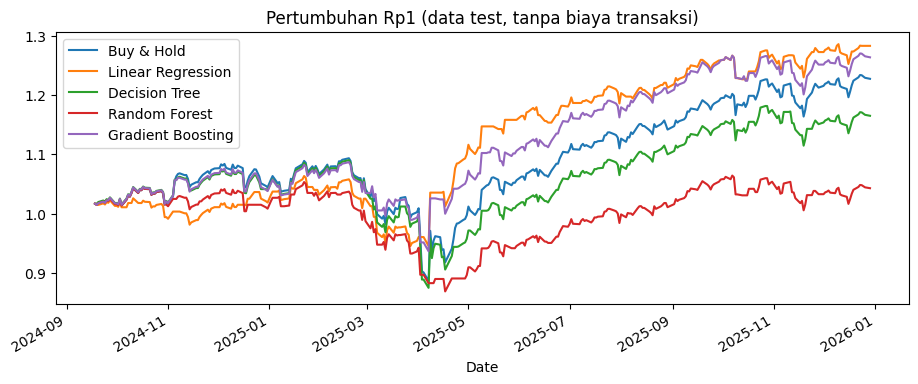

,2025-12-29
Linear Regression,1.283
Gradient Boosting,1.264
Buy & Hold,1.227
Decision Tree,1.165
Random Forest,1.043


In [10]:
bt = pd.DataFrame({"Buy & Hold": (1 + y_test).cumprod()})
for name in ["Linear Regression", "Decision Tree", "Random Forest", "Gradient Boosting"]:
    signal = (preds[name] > 0).astype(int)
    bt[name] = (1 + y_test * signal).cumprod()

bt.plot(figsize=(11, 4), title="Pertumbuhan Rp1 (data test, tanpa biaya transaksi)")
plt.show()
bt.iloc[-1].round(3).sort_values(ascending=False)

## 9. Walk-forward validation

Evaluasi sebelumnya memakai satu split tetap: model dilatih sekali lalu dipakai untuk seluruh periode test. Di praktik, model dilatih ulang secara berkala. Di sini memakai **expanding window**: model dilatih ulang tiap 21 hari bursa dengan semua data sampai saat itu, lalu memprediksi 21 hari berikutnya. Hyperparameter tetap memakai hasil tuning pada data train awal sehingga tidak ada kebocoran data dari periode test.

In [11]:
from sklearn.base import clone

REFIT_EVERY = 21     # hari bursa (~1 bulan)

def walk_forward(estimator, X, y, start, step=REFIT_EVERY):
    out = []
    for i in range(start, len(X), step):
        m = clone(estimator)
        m.fit(X.iloc[:i], y.iloc[:i])
        out.append(pd.Series(m.predict(X.iloc[i:i + step]), index=X.index[i:i + step]))
    return pd.concat(out)

# Pakai hyperparameter terbaik hasil tuning di train awal
fixed = {n: (m.best_estimator_ if hasattr(m, "best_estimator_") else m) for n, m in models.items()}
wf_preds = {n: walk_forward(est, X, y, split).values for n, est in fixed.items()}

def evaluate(pred_dict, y_true, close_t):
    act_price = close_t * (1 + y_true)
    rows = []
    for n, p in pred_dict.items():
        rows.append({"Model": n,
                     "MAE return": metrics.mean_absolute_error(y_true, p),
                     "RMSE return": np.sqrt(metrics.mean_squared_error(y_true, p)),
                     "R2 return": metrics.r2_score(y_true, p),
                     "Akurasi arah": np.mean(np.sign(p) == np.sign(y_true)),
                     "MAE harga": metrics.mean_absolute_error(act_price, close_t * (1 + p))})
    return pd.DataFrame(rows).set_index("Model").round(5).sort_values("MAE harga")

wf_results = evaluate(wf_preds, y_test, close_today)
wf_results

,MAE return,RMSE return,R2 return,Akurasi arah,MAE harga
Model,,,,,
Baseline (rata-rata train),0.00689,0.01102,-0.00099,0.57321,41.18623
Gradient Boosting,0.00689,0.01104,-0.00395,0.55452,41.20473
Decision Tree,0.00692,0.01084,0.03203,0.57321,41.38568
Ridge,0.00694,0.01098,0.00603,0.51402,41.50351
Random Forest,0.00696,0.01103,-0.00241,0.53583,41.61797
Linear Regression,0.00698,0.01087,0.02646,0.48910,41.80705


Uji Diebold-Mariano pada hasil walk-forward:

In [12]:
dm_table(wf_preds, y_test)

,DM (kuadrat),p (kuadrat),DM (absolut),p (absolut),Signifikan vs baseline?
Model,,,,,
Linear Regression,-0.8490,0.3965,0.9867,0.3245,tidak
Ridge,-0.6462,0.5186,1.5380,0.1250,tidak
Decision Tree,-0.7974,0.4258,0.2722,0.7856,tidak
Random Forest,0.1186,0.9056,1.8702,0.0624,tidak
Gradient Boosting,0.1145,0.9089,0.0274,0.9781,tidak


Backtest walk-forward **dengan biaya transaksi** (default 0,05% per perubahan posisi; ubah `COST` sesuai kebutuhan):

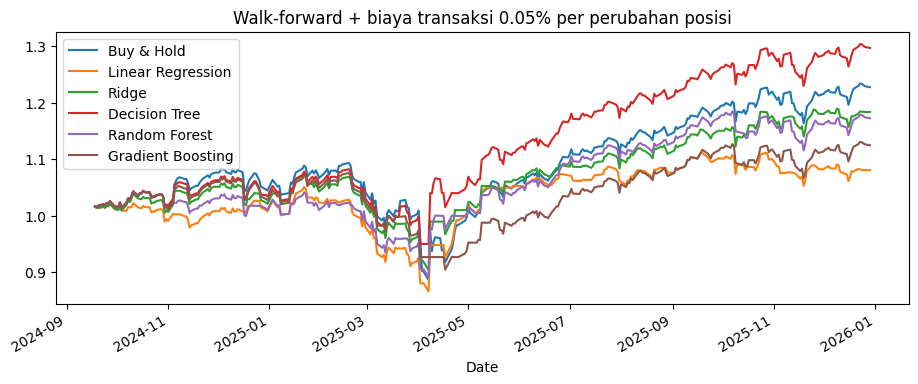

,Nilai akhir,Jumlah transaksi
Decision Tree,1.297,19.0
Buy & Hold,1.227,NaN
Ridge,1.184,80.0
Random Forest,1.173,49.0
Gradient Boosting,1.125,33.0
Linear Regression,1.081,108.0


In [13]:
COST = 0.0005

def strategy_returns(signal, ret, cost=COST):
    signal = pd.Series(signal, index=ret.index).astype(int)
    trades = signal.diff().abs().fillna(signal.abs())      # 1 jika posisi berubah
    return ret * signal - cost * trades, int(trades.sum())

bt_wf = pd.DataFrame({"Buy & Hold": (1 + y_test).cumprod()})
n_trades = {}
for name in ["Linear Regression", "Ridge", "Decision Tree", "Random Forest", "Gradient Boosting"]:
    r, n_t = strategy_returns(wf_preds[name] > 0, y_test)
    bt_wf[name] = (1 + r).cumprod()
    n_trades[name] = n_t

bt_wf.plot(figsize=(11, 4), title=f"Walk-forward + biaya transaksi {COST:.2%} per perubahan posisi")
plt.show()

summary = pd.DataFrame({"Nilai akhir": bt_wf.iloc[-1].round(3),
                        "Jumlah transaksi": pd.Series(n_trades)}).sort_values("Nilai akhir", ascending=False)
summary

## 10. Catatan tentang "forecast masa depan"

Versi lama memberi tanggal 2026 pada prediksi data test dan menyebutnya forecast. Itu keliru. Karena fitur memakai data lag, forecast banyak hari harus rekursif, dan galat menumpuk sehingga prediksi cepat konvergen ke nilai konstan (mendekati rata-rata return). Untuk 1 hari ke depan, cukup prediksi dari baris data terakhir.

Model dilatih ulang dengan **seluruh** data yang targetnya sudah diketahui (bukan hanya data train awal), sama seperti yang dilakukan walk-forward di bagian 9:

In [14]:
last_close = raw["Close"].iloc[-1]
final_model = clone(fixed[best_name]).fit(X, y)       # hyperparameter terbaik, dilatih di semua data
next_ret = final_model.predict(X_latest)[0]
print(f"{best_name}: prediksi return hari bursa berikutnya = {next_ret:.4%}")
print(f"Harga penutupan terakhir ({raw.index[-1].date()}): {last_close:,.2f}")
print(f"Implied harga berikutnya: {last_close * (1 + next_ret):,.2f}")

Gradient Boosting: prediksi return hari bursa berikutnya = 0.0659%
Harga penutupan terakhir (2025-12-30): 6,896.24
Implied harga berikutnya: 6,900.79


## Kesimpulan (isi setelah menjalankan)

- Bandingkan semua model terhadap baseline dan persistence, pada split tetap **dan** walk-forward.
- Lihat kolom `p` di uji Diebold-Mariano: selisih dengan p >= 0,05 tidak bisa dibedakan dari noise.
- Bandingkan akurasi arah dengan garis "selalu tebak naik", bukan hanya dengan 50%.
- Jika tidak ada model yang konsisten dan signifikan mengalahkan baseline, itu temuan yang valid: harga indeks saham sulit diprediksi dari fitur OHLCV historis.
- Ide lanjutan: tambah fitur eksternal (VIX, suku bunga), model deret waktu (ARIMA/GARCH).